# Random Forest Algorithm for Classifying Mobile Phone Price Ranges

in this case i will train the algorithm with the train.cs and try to predict the **price_range** from the mobile devices from the test.csv

**Obs**: in this, in specific, i can't know if my algorithm have good accuracy, precision an R², testing only with de test.csv, beacuse the test,csv doesn't have the column **price_range**. Thas why, in this case, i will split the train.csv in 2 parts, 80% to train e 20% to teste the metrics, and then, i will try to predict the **price_range** from the test.csv, assuming that the model has adjusted like the metrics of the training e test with the train.csv  

In [154]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split as tts
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.tree import export_graphviz
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

### Geting the data sets

In [155]:
train =  pd.read_csv('./train.csv')
real_test = pd.read_csv('./test.csv')

train.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


### Separating X and Y

In [156]:
y = train.iloc[:, -1]
x = train.drop(train.columns[-1], axis = 1).values

x

array([[8.420e+02, 0.000e+00, 2.200e+00, ..., 0.000e+00, 0.000e+00,
        1.000e+00],
       [1.021e+03, 1.000e+00, 5.000e-01, ..., 1.000e+00, 1.000e+00,
        0.000e+00],
       [5.630e+02, 1.000e+00, 5.000e-01, ..., 1.000e+00, 1.000e+00,
        0.000e+00],
       ...,
       [1.911e+03, 0.000e+00, 9.000e-01, ..., 1.000e+00, 1.000e+00,
        0.000e+00],
       [1.512e+03, 0.000e+00, 9.000e-01, ..., 1.000e+00, 1.000e+00,
        1.000e+00],
       [5.100e+02, 1.000e+00, 2.000e+00, ..., 1.000e+00, 1.000e+00,
        1.000e+00]], shape=(2000, 20))

### Spliting the train.csv on training and test, to analysis the metrics first:

In [157]:
labelEncoder = LabelEncoder()

for i in range (x.shape[1]):
    if x[:, i].dtype == 'object':
        x[:, i] = labelEncoder.fit_transform(x[:, i])

x_train, x_test, y_train, y_test = tts(
    x,
    y,
    test_size = 0.2,
    random_state=42
)

### Creating the model:

In [158]:
model = RandomForestClassifier(
    random_state = 1,
    max_depth = 20,
    max_leaf_nodes = 12,
    n_estimators = 500
)

model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: b

### See one of the trees:

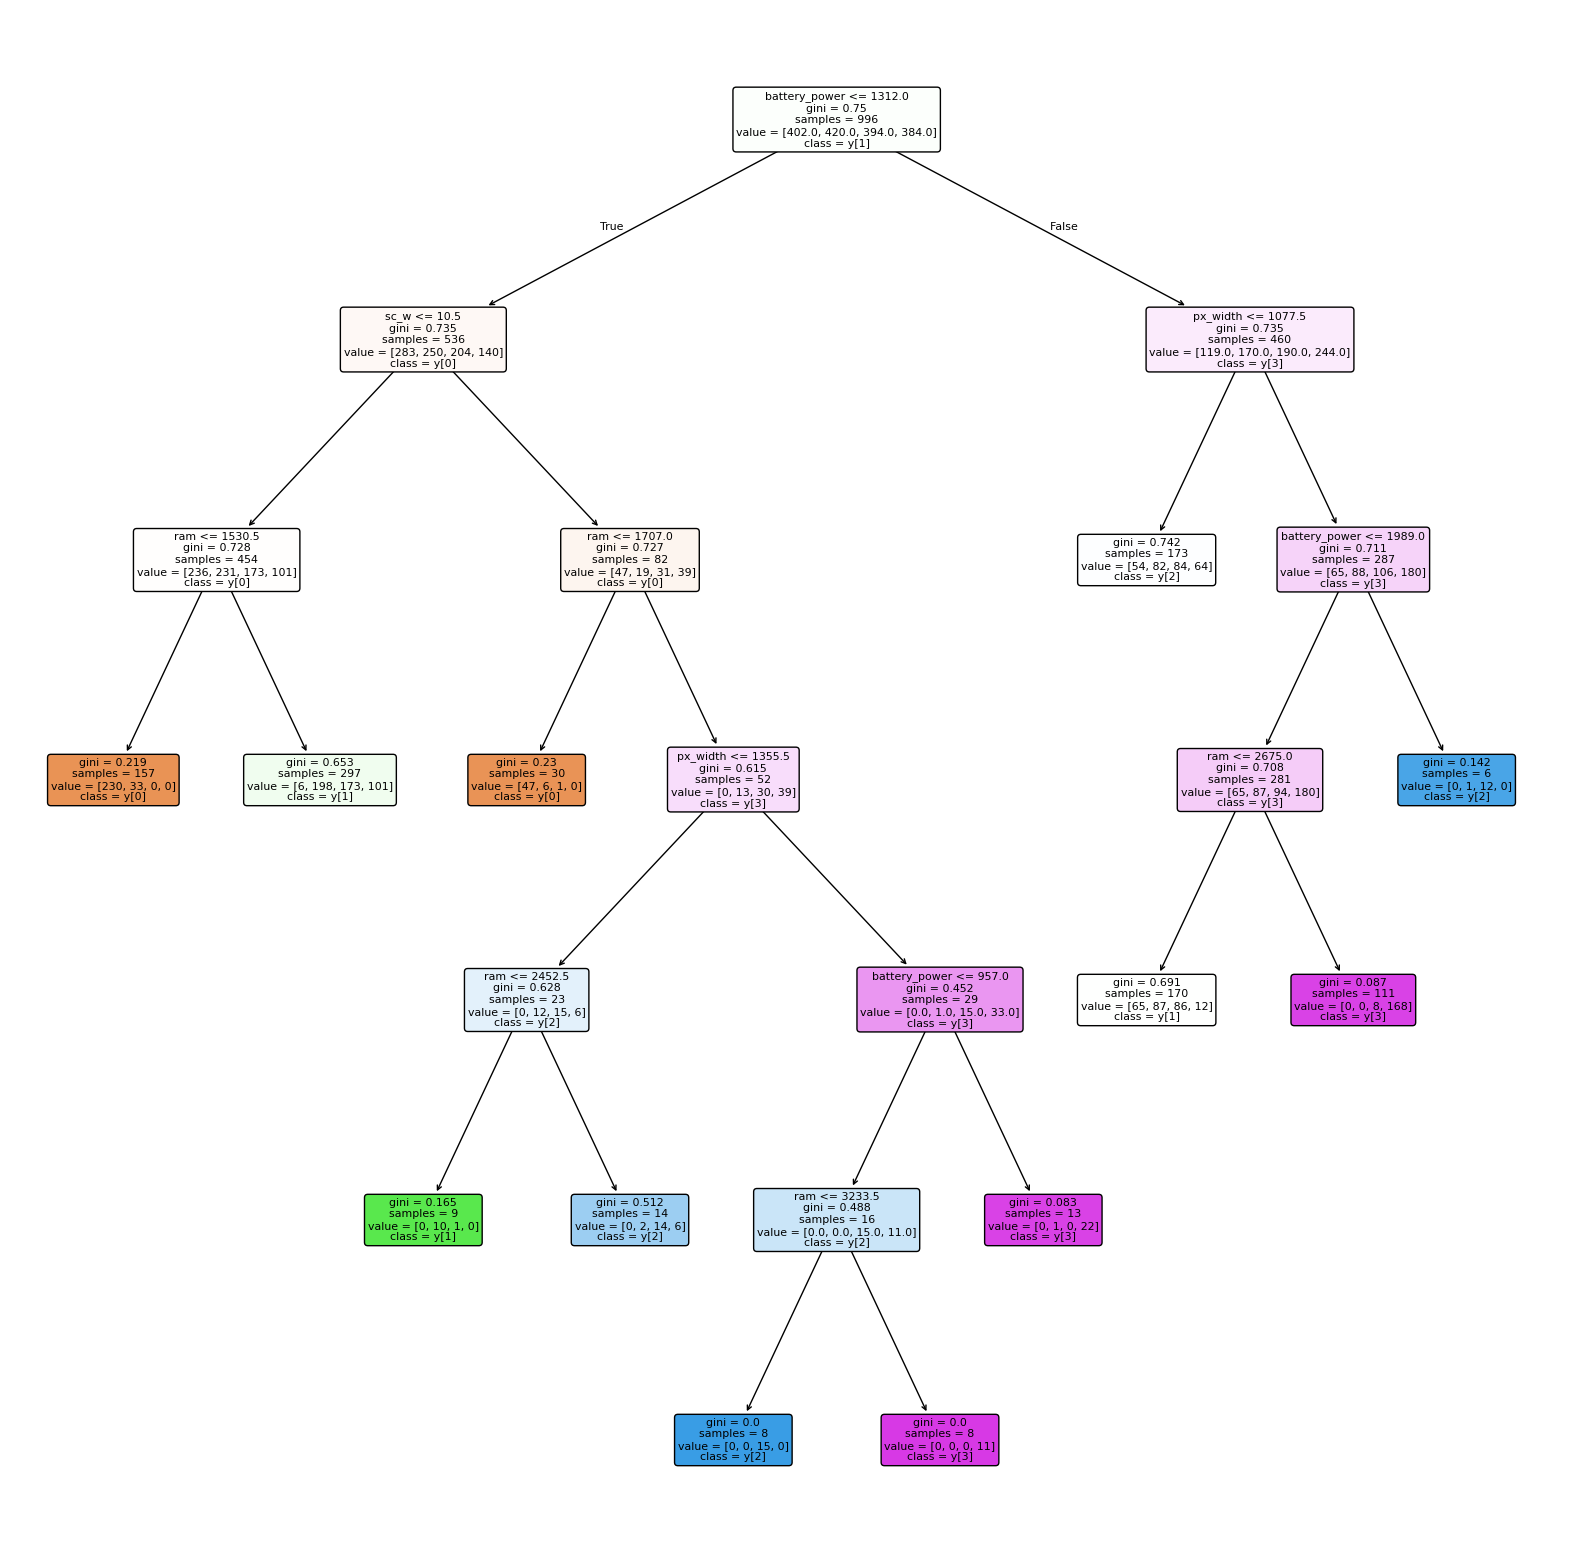

In [159]:
tree_index = 100

tree_to_visualize = model.estimators_[tree_index]
plt.figure(figsize=(20,20))
plot_tree(
    tree_to_visualize, 
    filled = True,
    feature_names = train.columns[:-1],
    class_names = True,
    rounded = True
    )

plt.show()

### Prediction with the 20% of the train.csv, to analysis the metrics:

In [160]:
model_to_analyze_metrics = model.predict(x_test)
model_to_analyze_metrics

array([0, 2, 1, 3, 1, 2, 2, 0, 3, 1, 0, 0, 2, 3, 2, 2, 3, 3, 1, 0, 0, 1,
       1, 1, 0, 1, 2, 2, 2, 0, 0, 0, 3, 0, 1, 1, 2, 0, 3, 0, 2, 3, 2, 0,
       3, 2, 2, 1, 3, 1, 3, 1, 0, 0, 1, 1, 1, 2, 0, 0, 0, 3, 3, 2, 0, 0,
       3, 3, 1, 2, 2, 3, 0, 1, 2, 0, 0, 3, 2, 2, 3, 2, 1, 0, 1, 3, 2, 3,
       3, 0, 3, 3, 2, 1, 3, 2, 2, 3, 2, 1, 0, 0, 1, 0, 0, 3, 2, 0, 1, 1,
       0, 0, 3, 1, 2, 2, 3, 3, 0, 2, 1, 3, 2, 1, 3, 3, 0, 3, 0, 2, 3, 0,
       2, 2, 0, 3, 1, 0, 0, 2, 3, 0, 2, 2, 0, 0, 0, 1, 2, 2, 3, 1, 1, 0,
       2, 2, 0, 1, 0, 2, 2, 3, 2, 3, 1, 0, 0, 2, 1, 3, 3, 1, 0, 0, 3, 1,
       1, 2, 1, 0, 0, 0, 0, 0, 3, 2, 0, 3, 0, 0, 0, 0, 1, 3, 3, 1, 0, 1,
       2, 1, 1, 2, 1, 2, 2, 3, 1, 2, 0, 0, 0, 1, 1, 1, 3, 1, 0, 2, 2, 1,
       3, 1, 3, 0, 0, 2, 1, 2, 0, 0, 1, 0, 1, 3, 2, 0, 1, 3, 3, 0, 1, 3,
       3, 3, 0, 3, 1, 2, 3, 3, 2, 1, 1, 3, 3, 1, 3, 3, 3, 3, 3, 0, 1, 2,
       2, 2, 2, 0, 2, 3, 2, 2, 2, 1, 0, 2, 0, 3, 3, 1, 3, 1, 0, 3, 1, 2,
       0, 0, 3, 0, 1, 2, 3, 3, 3, 0, 0, 0, 1, 3, 3,

### Analysing the metrics:

In [161]:
accuracy = accuracy_score(y_test, model_to_analyze_metrics)
precision = precision_score(y_test, model_to_analyze_metrics, average='weighted')
recall = recall_score(y_test, model_to_analyze_metrics, average='weighted')
f1 = f1_score(y_test, model_to_analyze_metrics, average='weighted')

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Accuracy: 0.8500
Precision: 0.8504
Recall: 0.8500
F1-Score: 0.8498


In [162]:
report = classification_report(y_test, model_to_analyze_metrics)
print(report)

              precision    recall  f1-score   support

           0       0.92      0.97      0.94       105
           1       0.80      0.78      0.79        91
           2       0.73      0.75      0.74        92
           3       0.92      0.88      0.90       112

    accuracy                           0.85       400
   macro avg       0.84      0.84      0.84       400
weighted avg       0.85      0.85      0.85       400



### Errors:

In [163]:
mask = (y_test != model_to_analyze_metrics).values

errors = pd.DataFrame(x_test[mask], columns=train.columns[:-1])
errors['actual'] = y_test[mask].values
errors['predicted'] = model_to_analyze_metrics[mask]



errors.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,actual,predicted
0,627.0,1.0,1.6,1.0,3.0,1.0,12.0,0.2,131.0,7.0,...,819.0,2476.0,17.0,1.0,10.0,1.0,0.0,0.0,1,2
1,1334.0,1.0,2.4,0.0,5.0,1.0,42.0,0.6,115.0,5.0,...,1974.0,2542.0,10.0,1.0,8.0,1.0,0.0,0.0,3,2
2,1288.0,0.0,0.5,1.0,3.0,1.0,61.0,0.2,115.0,6.0,...,1503.0,1882.0,16.0,6.0,10.0,1.0,0.0,1.0,2,1
3,1330.0,0.0,1.1,0.0,11.0,0.0,37.0,0.7,126.0,7.0,...,1637.0,2166.0,10.0,1.0,4.0,1.0,0.0,0.0,2,1
4,1880.0,0.0,0.5,0.0,0.0,1.0,7.0,0.6,104.0,4.0,...,1019.0,2968.0,9.0,0.0,3.0,1.0,1.0,0.0,3,2


### Confusion matrix:

In [164]:
matrix = confusion_matrix(y_test, model_to_analyze_metrics)

matrix_data = pd.DataFrame(matrix,
    index = [f'actual_{i}' for i in range(matrix.shape[0])],
    columns = [f'predicted_{i}' for i in range(matrix.shape[1])]
)

matrix_data

,predicted_0,predicted_1,predicted_2,predicted_3
actual_0,102,3,0,0
actual_1,9,71,11,0
actual_2,0,15,69,8
actual_3,0,0,14,98


### Executing the real prediction with the test.csv:
- i'm assuming that the real prediction have about 85% of accuracy, and precision, like the prediction with the 20% of the train.csv used to get the metrics.

In [165]:
filtred_data = real_test.drop(columns='id').values

real_prediction = model.predict(filtred_data)
real_prediction

array([3, 3, 2, 3, 1, 3, 3, 1, 3, 0, 3, 3, 0, 0, 2, 0, 1, 1, 3, 2, 1, 3,
       1, 1, 3, 0, 2, 0, 2, 0, 2, 0, 3, 0, 0, 1, 3, 1, 2, 1, 1, 2, 0, 0,
       0, 1, 0, 3, 1, 2, 2, 0, 3, 0, 3, 1, 3, 1, 1, 3, 3, 2, 0, 1, 1, 1,
       1, 2, 1, 1, 1, 1, 2, 3, 3, 0, 2, 0, 2, 3, 0, 3, 3, 0, 3, 0, 3, 1,
       3, 0, 1, 1, 2, 1, 2, 1, 0, 2, 1, 2, 1, 0, 0, 3, 1, 2, 0, 1, 2, 3,
       3, 3, 1, 3, 3, 3, 3, 1, 3, 0, 0, 3, 2, 1, 1, 0, 3, 2, 3, 1, 0, 1,
       1, 1, 3, 1, 1, 0, 3, 2, 1, 3, 2, 2, 2, 3, 3, 2, 2, 3, 2, 3, 0, 0,
       2, 2, 3, 3, 3, 3, 3, 2, 3, 3, 3, 3, 1, 0, 3, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 2, 0, 0, 0, 0, 2, 2, 2, 1, 0, 0, 0, 0, 0, 3, 1, 0, 2, 2,
       2, 3, 1, 2, 3, 3, 3, 1, 2, 1, 0, 0, 1, 2, 0, 2, 3, 3, 0, 2, 0, 3,
       2, 3, 3, 0, 0, 1, 0, 3, 0, 1, 0, 2, 1, 1, 3, 0, 3, 0, 3, 1, 2, 0,
       0, 2, 1, 3, 2, 3, 1, 1, 3, 0, 0, 2, 3, 3, 1, 3, 1, 0, 3, 2, 1, 2,
       3, 3, 3, 1, 0, 1, 1, 3, 1, 1, 3, 2, 0, 3, 0, 1, 2, 0, 0, 3, 2, 3,
       3, 2, 1, 3, 3, 2, 3, 2, 2, 1, 1, 0, 2, 3, 1,